<a href="https://colab.research.google.com/github/leman973/Deep-Learning/blob/main/Pract_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Input,Dropout


In [2]:
train_df = pd.read_csv("sign_mnist_train.csv")

In [3]:
test_df = pd.read_csv("sign_mnist_test.csv")

In [4]:
y_train = train_df["label"].values

In [5]:
x_train = train_df.drop("label",axis=1).values

In [6]:
y_test = test_df["label"].values
x_test = test_df.drop("label",axis=1).values

In [7]:
x_train = x_train.reshape(-1,28,28)
x_test = x_test.reshape(-1,28,28)

In [8]:
print("x_train shape is: ",x_train.shape)
print("x_test shape is: ", x_test.shape)

x_train shape is:  (27455, 28, 28)
x_test shape is:  (7172, 28, 28)


In [9]:
x_train = x_train/255.0
x_test = x_test/255.0

In [10]:
model = Sequential([
    Input(shape=(28,28,1)),

    Conv2D(32,(3,3),activation = "relu"),
    MaxPooling2D((2,2)),

    Conv2D(64,(3,3),activation = "relu"),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(128,activation = "relu"),
    Dropout(0.3),
    Dense(25,activation = "softmax")
])

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,969 (886.60 KB)

 Trainable params: 226,969 (886.60 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [13]:
history = model.fit(x_train, y_train, epochs = 10, batch_size = 64, validation_split = 0.1)

Epoch 1/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 23s 56ms/step - accuracy: 0.4738 - loss: 1.7125 - val_accuracy: 0.8481 - val_loss: 0.5032
Epoch 2/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 23s 60ms/step - accuracy: 0.8425 - loss: 0.4852 - val_accuracy: 0.9712 - val_loss: 0.1297
Epoch 3/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.9324 - loss: 0.2177 - val_accuracy: 0.9971 - val_loss: 0.0425
Epoch 4/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9607 - loss: 0.1272 - val_accuracy: 0.9989 - val_loss: 0.0199
Epoch 5/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 41s 57ms/step - accuracy: 0.9754 - loss: 0.0813 - val_accuracy: 1.0000 - val_loss: 0.0077
Epoch 6/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 41s 58ms/step - accuracy: 0.9790 - loss: 0.0662 - val_accuracy: 1.0000 - val_loss: 0.0057
Epoch 7/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.9852 - loss: 0.0483 - val_accuracy: 1.0000 - val_loss: 0.0034
Epoch 8/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 23s 58ms/step - accuracy: 0.9845 - loss: 0.0484 - 

In [14]:
import matplotlib.pyplot as plt

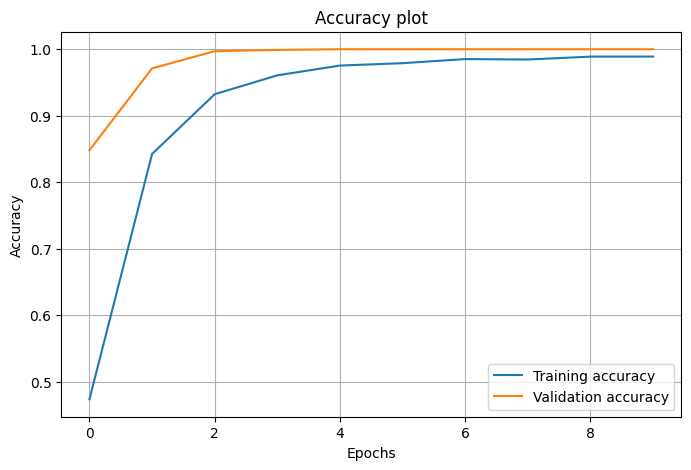

In [15]:
plt.figure(figsize = (8,5))
plt.plot(history.history["accuracy"],label = "Training accuracy")
plt.plot(history.history["val_accuracy"], label = "Validation accuracy")

plt.title("Accuracy plot")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

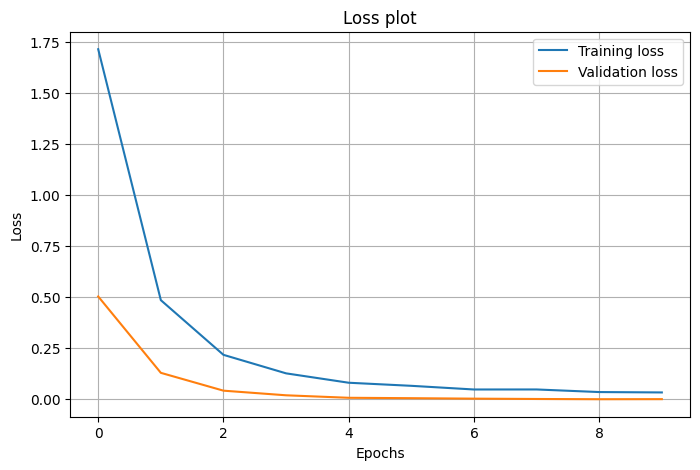

In [16]:
plt.figure(figsize = (8,5))
plt.plot(history.history["loss"], label = "Training loss")
plt.plot(history.history["val_loss"], label = "Validation loss")

plt.title("Loss plot")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [17]:
test_loss, test_accuracy = model.evaluate(x_test,y_test)

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9169 - loss: 0.2911


In [18]:
predict = model.predict(x_test)
prediction = np.argmax(predict, axis = 1)

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


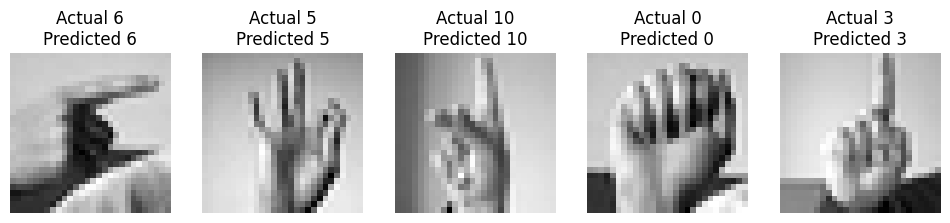

In [19]:
plt.figure(figsize=(12,5))
for i in range(5):
  plt.subplot(1,5,i+1)
  plt.imshow(x_test[i].reshape(28,28),cmap="gray")
  plt.title(f"Actual {y_test[i]}\nPredicted {prediction[i]}")
  plt.axis("off")
plt.show()


In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

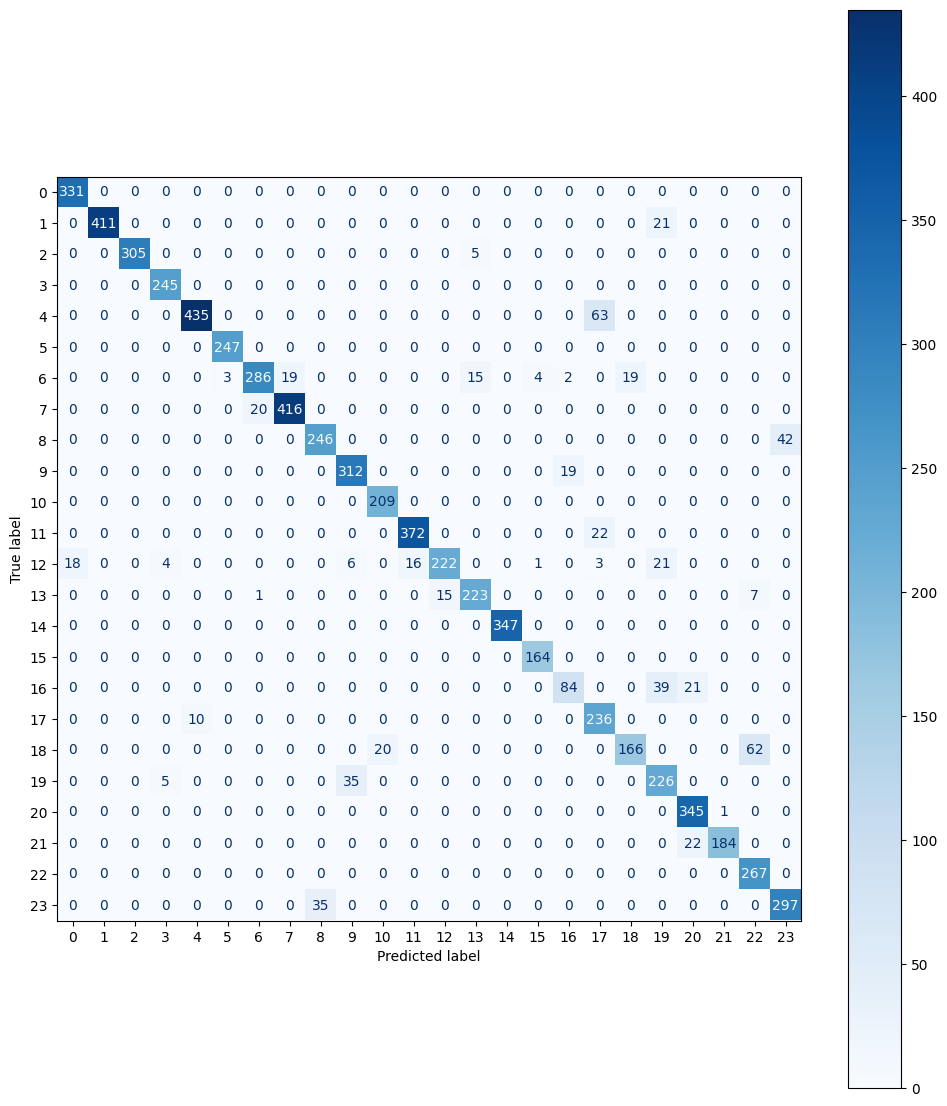

In [21]:
plt.figure(figsize=(12,14))
cm = confusion_matrix(y_test,prediction)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues",ax = plt.gca())
plt.show()